# Data Cleaning
UFC fight stats dataset — cleaning before modeling.

## 1. Load Data

In [2]:
%pip install pandas numpy matplotlib seaborn scikit-learn regex

Note: you may need to restart the kernel to use updated packages.


In [30]:
import pandas as pd
import numpy as np
import regex as re
from matplotlib import pyplot as plt
import seaborn as sns

In [4]:


fights = pd.read_csv('../data/raw/ufc_event_fight_stats.csv')
fighters = pd.read_csv('../data/raw/ufc_fighters.csv')
events = pd.read_csv('../data/raw/ufc_events.csv')

print(fights.shape, fighters.shape, events.shape)

(7840, 58) (4262, 19) (711, 4)


## 2. Initial Overview
Get a feel for the data — column types, missing values, basic stats.

In [5]:
# Check dtypes and non-null counts
# fights.info()

In [6]:
# Count missing values per column
# fights.isnull().sum()

In [7]:
# Quick look at a few rows
# fights.head()

## 3. Handle Missing Values

In [8]:
# fighters.csv also has NaN for these fighters — can't use to fill in missing values.
# Strategy:
#   height    -> drop rows (only 16 rows, height is meaningful so don't impute)
#   age       -> fill with median (less critical, small number missing)
#   *** CONNOR DOES THIS MAKE SENSE??? ****: ctrl_time -> fill with 0 (no control recorded = 0 seconds) 

# --- Height: drop rows with missing height ---
before = len(fights)
fights.dropna(subset=['f1_height_cm', 'f2_height_cm'], inplace=True)
print(f'Dropped {before - len(fights)} rows with missing height. Remaining: {len(fights)}')

# --- Age: fill with median ---
fights['f1_age_during'] = fights['f1_age_during'].fillna(fights['f1_age_during'].median())
fights['f2_age_during'] = fights['f2_age_during'].fillna(fights['f2_age_during'].median())

# --- Control time: fill with 0 ---
fights['f1_ctrl_time'] = fights['f1_ctrl_time'].fillna(0)
fights['f2_ctrl_time'] = fights['f2_ctrl_time'].fillna(0)

# Verify — all should be 0
print(fights[['f1_height_cm','f2_height_cm','f1_age_during','f2_age_during','f1_ctrl_time','f2_ctrl_time']].isnull().sum())

Dropped 16 rows with missing height. Remaining: 7824
f1_height_cm     0
f2_height_cm     0
f1_age_during    0
f2_age_during    0
f1_ctrl_time     0
f2_ctrl_time     0
dtype: int64


All fields in ``fights`` should have no null values here.

## 4. Data Types

In [9]:
# date columns to datetime
events['event_date'] = pd.to_datetime(events['event_date'])
fighters['fighter_dob'] = pd.to_datetime(fighters['fighter_dob'])

# result of 'nc' (no contest) to NaN, then dropped those rows
fights['result'] = pd.to_numeric(fights['result'], errors='coerce').astype('Int64')
before = len(fights)
fights.dropna(subset=['result'], inplace=True)
print(f'Dropped {before - len(fights)} no-contest rows. Remaining: {len(fights)}')

Dropped 143 no-contest rows. Remaining: 7681


## 5. Target Column
`result` holds the winner's fighter_id.
Now `winner` holds 1 if f1 wins, 0 if f2 wins

In [10]:
# target variable
fights['winner'] = (fights['result'] == fights['f1_id']).astype(int)

## 6. Remove Irrelevant Columns

In [11]:
fights.drop(columns=['fights_url', 'event_url', 'result'], inplace=True)

## 7. Handle Categorical Columns
encodes `weight class` as follows:
| Encoding | Men's | Women's |
|----------|-------|---------|
| 0 | Flyweight | Flyweight |
| 1 | Bantamweight | Strawweight |
| 2 | Featherweight | Bantamweight |
| 3 | Lightweight | Featherweight |
| 4 | Welterweight | |
| 5 | Middleweight | |
| 6 | Light Heavyweight | |
| 7 | Heavyweight | |
| 8 | Catch Weight | |

adds `is_title_bout`

In [12]:
# Check unique weight classes
# pd.set_option("display.max_rows", None)
# fights['weight_class'].value_counts()

In [13]:
is_womens = fights['weight_class'].str.contains("Women's")

# MEN'S (0-8)
mens_conditions = [
    fights['weight_class'].str.contains('Flyweight') & ~is_womens,         # 0
    fights['weight_class'].str.contains('Bantamweight') & ~is_womens,      # 1
    fights['weight_class'].str.contains('Featherweight') & ~is_womens,     # 2
    fights['weight_class'].str.contains('Lightweight') & ~is_womens,       # 3
    fights['weight_class'].str.contains('Welterweight') & ~is_womens,      # 4
    fights['weight_class'].str.contains('Middleweight') & ~is_womens,      # 5
    fights['weight_class'].str.contains('Light Heavyweight') & ~is_womens, # 6
    fights['weight_class'].str.contains('Heavyweight') & ~is_womens,       # 7
    fights['weight_class'].str.contains('Catch Weight') & ~is_womens,      # 8
]

# WOMEN'S (0-3)
womens_conditions = [
    is_womens & fights['weight_class'].str.contains('Flyweight'),      # 0
    is_womens & fights['weight_class'].str.contains('Strawweight'),    # 1
    is_womens & fights['weight_class'].str.contains('Bantamweight'),   # 2
    is_womens & fights['weight_class'].str.contains('Featherweight'),  # 3
]

fights['mens_class_encoded'] = np.select(mens_conditions, [0,1,2,3,4,5,6,7,8], default=-1)
fights['womens_class_encoded'] = np.select(womens_conditions, [0,1,2,3], default=-1)

# is a title bout
fights['is_title_bout'] = fights['weight_class'].str.contains('Title')

## 8. Check for Duplicates

In [ ]:
# no duplicates
print(fights.duplicated().sum())

0


## 9. Check for Outliers
Look at numeric columns for extreme values that may be errors.

In [24]:
# Basic stats to spot outliers
d = fights.describe()
d

,f1_id,f2_id,f1_age_during,f2_age_during,f1_height_cm,f2_height_cm,f1_knockdowns,f2_knockdowns,f1_sig_strike_atts,f2_sig_strike_atts,...,f2_clinchs,f1_ground_atts,f2_ground_atts,f1_grounds,f2_grounds,f1_total_fight_time,f2_total_fight_time,winner,mens_class_encoded,womens_class_encoded
count,7681.000000,7681.000000,7681.000000,7681.000000,7681.000000,7681.000000,7681.000000,7681.000000,7681.000000,7681.000000,...,7681.000000,7681.000000,7681.000000,7681.000000,7681.000000,7681.000000,7681.000000,7681.000000,7681.000000,7681.000000
mean,2109.967192,2107.250098,30.005598,29.634553,178.493779,178.400526,0.247233,0.182528,85.244239,79.936727,...,4.761359,8.844161,5.561646,6.091785,3.792215,635.863690,635.863690,0.645879,3.255956,-0.787658
std,1218.958985,1215.633297,4.251635,4.032892,9.050465,8.956307,0.520855,0.458442,71.638893,69.281398,...,6.840782,14.485537,11.161113,9.961333,7.884257,362.117897,362.117897,0.478277,2.390323,0.680329
min,4.000000,2.000000,18.000000,18.000000,152.400000,152.400000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,5.000000,0.000000,-1.000000,-1.000000
25%,1043.000000,1037.000000,27.000000,27.000000,172.720000,172.720000,0.000000,0.000000,30.000000,25.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,281.000000,281.000000,0.000000,2.000000,-1.000000
50%,2144.000000,2121.000000,30.000000,29.000000,177.800000,177.800000,0.000000,0.000000,68.000000,63.000000,...,2.000000,3.000000,1.000000,2.000000,1.000000,819.000000,819.000000,1.000000,3.000000,-1.000000
75%,3125.000000,3146.000000,33.000000,32.000000,185.420000,185.420000,0.000000,0.000000,122.000000,117.000000,...,6.000000,11.000000,6.000000,8.000000,4.000000,900.000000,900.000000,1.000000,5.000000,-1.000000
max,4256.000000,4261.000000,51.000000,51.000000,210.820000,210.820000,5.000000,4.000000,744.000000,510.000000,...,78.000000,141.000000,163.000000,97.000000,136.000000,1500.000000,1500.000000,1.000000,8.000000,3.000000


**Fighter 1 wins 64.59% of the time in our data set. This is why we need to duplicate fights for symmetry."**

In [ ]:
round(float(d['winner']['mean']), 4)*100

64.59

<Axes: >

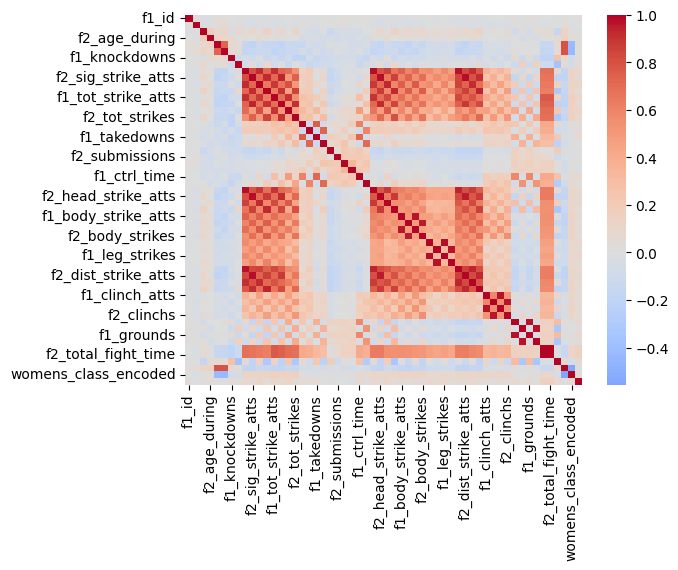

In [37]:
sns.heatmap(fights.corr(numeric_only=True), fmt=".2f", cmap="coolwarm", center=0)

In [ ]:
corr_matrix = fights.corr(numeric_only=True)

threshold = 0.7
pairs = (corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)).stack().reset_index())
pairs.columns = ['feature_1', 'feature_2', 'correlation']
pairs = pairs[pairs['correlation'].abs() > threshold].sort_values('correlation', ascending=False)

print(f"There are {len(pairs)} pairs of fields with correlation greater than {threshold}")
pd.set_option('display.max_rows', 50)
pairs

There are 113 pairs of fields with correlation greater than 0.7


,feature_1,feature_2,correlation
2851,f1_total_fight_time,f2_total_fight_time,1.000000
1940,f1_leg_strike_atts,f1_leg_strikes,0.979796
531,f2_sig_strike_atts,f2_head_strike_atts,0.979174
474,f1_sig_strike_atts,f1_head_strike_atts,0.977600
543,f2_sig_strike_atts,f2_dist_strike_atts,0.976205
...,...,...,...
587,f1_sig_strikes,f2_head_strike_atts,0.702622
462,f1_sig_strike_atts,f1_tot_strikes,0.702187
1775,f2_body_strike_atts,f2_dist_strike_atts,0.701801
834,f1_tot_strikes,f1_total_fight_time,0.701489


### Other Findings

Most fights have 0 knowckdowns. Fights with 1 or more knockdowns are outliers that we may need to consider.

In [52]:
fights['f1_knockdowns'].value_counts()

f1_knockdowns
0    6056
1    1393
2     199
3      26
4       5
5       2
Name: count, dtype: int64

{'whiskers': [<matplotlib.lines.Line2D at 0x25a6359d340>,
 'caps': [<matplotlib.lines.Line2D at 0x25a6359d820>,
 'boxes': [<matplotlib.lines.Line2D at 0x25a6359d0a0>],
 'medians': [<matplotlib.lines.Line2D at 0x25a6359ddc0>],
 'fliers': [<matplotlib.lines.Line2D at 0x25a6359e060>],
 'means': []}

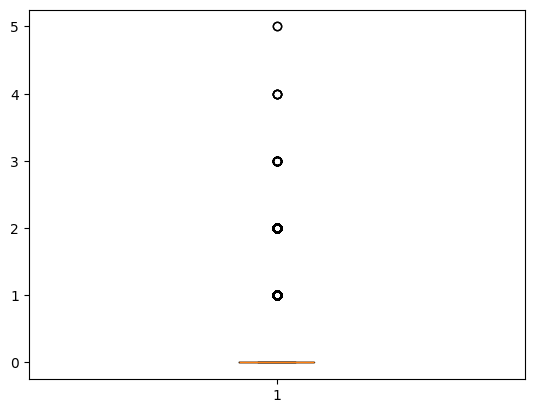

In [ ]:
plt.boxplot(fights['f1_knockdowns'],)

(array([6.056e+03, 0.000e+00, 1.393e+03, 0.000e+00, 1.990e+02, 0.000e+00,
        2.600e+01, 0.000e+00, 5.000e+00, 2.000e+00]),
 array([0. , 0.5, 1. , 1.5, 2. , 2.5, 3. , 3.5, 4. , 4.5, 5. ]),
 <BarContainer object of 10 artists>)

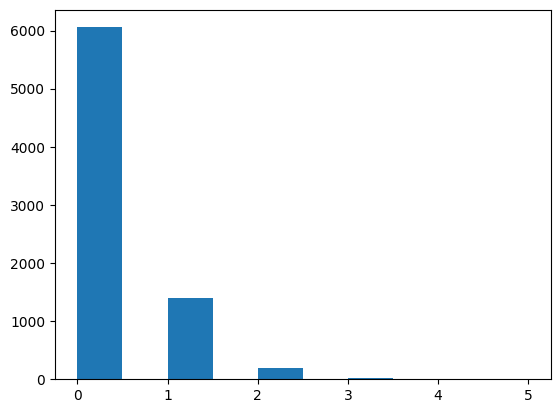

In [53]:
plt.hist(fights['f1_knockdowns'])

## Save Cleaned Data

In [58]:
fights.to_csv('../data/processed/fights_cleaned.csv', index=False)
print('Cleaned data saved to processed/flights_cleaned.csv with shape:', fights.shape)

Cleaned data saved to processed/flights_cleaned.csv with shape: (7681, 59)
